In [1]:
%pip install monai

from google.colab import drive
drive.mount('/content/drive')

import sys, json
sys.path.append('/content/drive/MyDrive/TFM')

import evaluacion as ev

# 1. Cargar la partición y quedarnos con el TEST (nunca usado hasta ahora)
with open('/content/drive/MyDrive/TFM/ISLES-2022_Preprocessed_v2/dataset_split.json') as f:
    split = json.load(f)
ids_test = [ev.id_base(s) for s in split['test']]
print(f"Test: {len(ids_test)} sujetos")

# 2. Copiar el test a disco local (idempotente, se puede relanzar)
DIR_DRIVE = '/content/drive/MyDrive/TFM/ISLES-2022_Preprocessed_v2'
DIR_NPY_TEST = '/content/npy_test'
ev.preparar_test(ids_test, DIR_DRIVE, DIR_NPY_TEST)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 17.5 MB/s  0:00:00
Mounted at /content/drive
Test: 50 sujetos
  10/50 sujetos de test | disco libre 251.6 GB
  20/50 sujetos de test | disco libre 250.4 GB
  30/50 sujetos de test | disco libre 249.1 GB
  40/50 sujetos de test | disco libre 247.7 GB
  50/50 sujetos de test | disco libre 246.4 GB


In [ ]:
# 3. Evaluar los 4 modelos sobre cada paciente (se reanuda solo si se desconecta)
RUTA_CSV = '/content/drive/MyDrive/TFM/resultados/evaluacion_test.csv'
params = ev.evaluar(ids_test, DIR_NPY_TEST, '/content/drive/MyDrive/TFM/resultados',
                    RUTA_CSV, device="cuda")

# 4. Tabla resumen (media±DE, mediana[Q1-Q3])
tabla = ev.resumen(RUTA_CSV, params)
tabla.to_csv('/content/drive/MyDrive/TFM/resultados/tabla_resumen.csv', index=False)
tabla

# 5. Comparación pareada por paciente (repite para cada métrica que quieras probar)
ev.comparar_pares(RUTA_CSV, "dice")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test: 50 sujetos
  10/50 sujetos de test | disco libre 200.8 GB
  20/50 sujetos de test | disco libre 199.6 GB
  30/50 sujetos de test | disco libre 198.3 GB
  40/50 sujetos de test | disco libre 197.0 GB
  50/50 sujetos de test | disco libre 195.7 GB
Parámetros: {'UNet_2D': '660,281', 'AttentionUNet_2D': '1,987,705', 'SegNet_2D': '1,769,729', 'VNet_2D': '9,359,124'}
[1/50] sub-strokecase0143 | UNet_2D: Dice 0.251 | AttentionUNet_2D: Dice 0.352 | SegNet_2D: Dice 0.386 | VNet_2D: Dice 0.175
[2/50] sub-strokecase0007 | UNet_2D: Dice 0.057 | AttentionUNet_2D: Dice 0.063 | SegNet_2D: Dice 0.064 | VNet_2D: Dice 0.060
[3/50] sub-strokecase0098 | UNet_2D: Dice 0.287 | AttentionUNet_2D: Dice 0.271 | SegNet_2D: Dice 0.364 | VNet_2D: Dice 0.446
[4/50] sub-strokecase0061 | UNet_2D: Dice 0.438 | AttentionUNet_2D: Dice 0.342 | SegNet_2D: Dice 0.433 | VNet_2D: Dice 0.783
[

,metrica,A,B,n_pares,mediana_A-B,media_A-B,IC95_inf,IC95_sup,p_wilcoxon,p_holm
0,dice,AttentionUNet_2D,SegNet_2D,50,0.033827,0.018478,-0.009810,0.045623,0.136983,0.410949
1,dice,AttentionUNet_2D,UNet_2D,50,-0.000336,0.003600,-0.012919,0.020385,0.980160,0.980160
2,dice,AttentionUNet_2D,VNet_2D,50,-0.046180,-0.084674,-0.130665,-0.041640,0.000733,0.002930
3,dice,SegNet_2D,UNet_2D,50,-0.019535,-0.014878,-0.040783,0.012762,0.201169,0.410949
4,dice,SegNet_2D,VNet_2D,50,-0.110261,-0.103152,-0.140739,-0.065783,0.000005,0.000028
5,dice,UNet_2D,VNet_2D,50,-0.053357,-0.088274,-0.129075,-0.051343,0.000010,0.000051


In [ ]:
# =============================================================================
# CELDA DE VALIDACIÓN — hd95_mm y metricas_volumen
# Verifica las funciones de métricas ANTES de usarlas sobre el conjunto de test.
# Requiere que 'evaluacion.py' ya esté importado como 'ev' en este notebook.
# =============================================================================
import numpy as np
from scipy.spatial.distance import cdist
from scipy.ndimage import binary_erosion
import evaluacion as ev   # <-- ajusta si tu import tiene otro alias

resultados = []

# -----------------------------------------------------------------------------
# 1) VALIDACIÓN DE hd95_mm: implementación de fuerza bruta independiente
# -----------------------------------------------------------------------------
def superficie(mask):
    """Vóxeles del borde: pertenecen a la máscara pero tienen al menos un vecino fuera de ella."""
    erosionado = binary_erosion(mask)
    return mask.astype(bool) & ~erosionado

def hd95_fuerza_bruta(pred, gt, spacing):
    pred_sup, gt_sup = superficie(pred), superficie(gt)
    pts_pred = np.array(np.nonzero(pred_sup)).T * np.array(spacing)
    pts_gt   = np.array(np.nonzero(gt_sup)).T * np.array(spacing)
    if len(pts_pred) == 0 or len(pts_gt) == 0:
        return np.nan
    d = cdist(pts_pred, pts_gt)
    d_pred_a_gt = d.min(axis=1)
    d_gt_a_pred = d.min(axis=0)
    return max(np.percentile(d_pred_a_gt, 95), np.percentile(d_gt_a_pred, 95))

def generar_par(forma, offset, size=(12, 12, 12)):
    """Genera (pred, gt) binarios sintéticos: un cubo y una versión desplazada/reducida."""
    gt = np.zeros(size, dtype=np.uint8)
    gt[3:9, 3:9, 3:9] = 1
    pred = np.zeros(size, dtype=np.uint8)
    dx, dy, dz = offset
    sl = tuple(slice(max(0, 3+d), min(size[i], 9+d)) for i, d in enumerate(offset))
    pred[sl] = 1
    if forma == "erosionado":
        pred[4:8, 4:8, 4:8] = 1
        pred[3:9, 3:9, 3:9] = 0
        pred[4:8, 4:8, 4:8] = 1
    return pred, gt

offsets = [(0, 0, 0), (1, 0, 0), (2, 1, 0), (1, 1, 1), (0, 2, 1), (3, 0, 2)]
espaciados = [(1.0, 1.0, 1.0), (1.0, 1.0, 2.0), (0.5, 0.5, 0.5)]

print("=== 1) hd95_mm vs. fuerza bruta (18 casos: 6 pares x 3 espaciados) ===")
n_ok = 0
for i, off in enumerate(offsets):
    pred, gt = generar_par("desplazado", off)
    for sp in espaciados:
        h_oficial = ev.hd95_mm(pred, gt, sp)
        h_bruto = hd95_fuerza_bruta(pred, gt, sp)
        ok = np.isclose(h_oficial, h_bruto, atol=1e-6)
        n_ok += int(ok)
        if not ok:
            print(f"  [FALLO] offset={off} spacing={sp}: oficial={h_oficial:.4f} bruto={h_bruto:.4f}")
print(f"  Resultado: {n_ok}/18 casos coinciden exactamente.")
resultados.append(("hd95_mm vs fuerza bruta", n_ok == 18))

# -----------------------------------------------------------------------------
# 2) VALIDACIÓN DE metricas_volumen: caso calculado a mano
# -----------------------------------------------------------------------------
print("\n=== 2) metricas_volumen vs. cálculo manual (matriz de confusión) ===")
gt = np.zeros((4, 4, 4), dtype=np.uint8)
gt[1:3, 1:3, 1:3] = 1          # 8 vóxeles de lesión real

pred = np.zeros((4, 4, 4), dtype=np.uint8)
pred[1:3, 1:3, 1:2] = 1        # 4 vóxeles correctos (VP)
pred[0, 0, 0] = 1              # 1 vóxel falso positivo (FP)
# FN = 8 - 4 = 4 ; VN = 64 - (VP+FP+FN) = 64 - 4 - 1 - 4 = 55

VP, FP, FN, VN = 4, 1, 4, 55
dice_esperado = 2*VP / (2*VP + FP + FN)
jaccard_esperado = VP / (VP + FP + FN)
sens_esperado = VP / (VP + FN)
espec_esperado = VN / (VN + FP)
prec_esperado = VP / (VP + FP)

m = ev.metricas_volumen(pred, gt, spacing=(1.0, 1.0, 1.0))
checks_manual = {
    "dice": (m["dice"], dice_esperado),
    "jaccard": (m["jaccard"], jaccard_esperado),
    "sensibilidad": (m["sensibilidad"], sens_esperado),
    "especificidad": (m["especificidad"], espec_esperado),
    "precision": (m["precision"], prec_esperado),
}
ok_manual = True
for nombre, (obtenido, esperado) in checks_manual.items():
    ok = np.isclose(obtenido, esperado, atol=1e-6)
    ok_manual &= ok
    print(f"  {nombre}: obtenido={obtenido:.4f} | esperado={esperado:.4f} | {'OK' if ok else 'FALLO'}")
resultados.append(("metricas_volumen vs cálculo manual", ok_manual))

# -----------------------------------------------------------------------------
# 3) VALIDACIÓN DE metricas_volumen: caso límite — predicción vacía
# -----------------------------------------------------------------------------
print("\n=== 3) metricas_volumen — caso límite: predicción vacía (sin lesión predicha) ===")
gt_vacio = np.zeros((4, 4, 4), dtype=np.uint8)
gt_vacio[1:3, 1:3, 1:3] = 1
pred_vacio = np.zeros((4, 4, 4), dtype=np.uint8)   # el modelo no predice NADA

try:
    m_vacio = ev.metricas_volumen(pred_vacio, gt_vacio, spacing=(1.0, 1.0, 1.0))
    sin_nan = not any(np.isnan(v) for v in m_vacio.values() if isinstance(v, (int, float)))
    sens_ok = np.isclose(m_vacio["sensibilidad"], 0.0)
    dice_ok = np.isclose(m_vacio["dice"], 0.0)
    print(f"  Dice={m_vacio['dice']:.4f} | Sensibilidad={m_vacio['sensibilidad']:.4f} | "
          f"Precisión={m_vacio['precision']:.4f} | pred_vacia={m_vacio.get('pred_vacia')}")
    ok_vacio = sin_nan and sens_ok and dice_ok
    print(f"  Resultado: {'OK (sin NaN, valores coherentes)' if ok_vacio else 'FALLO'}")
except Exception as e:
    ok_vacio = False
    print(f"  [FALLO] La función lanzó una excepción con predicción vacía: {e}")
resultados.append(("metricas_volumen — predicción vacía", ok_vacio))

# -----------------------------------------------------------------------------
# RESUMEN FINAL
# -----------------------------------------------------------------------------
print("\n" + "="*60)
print("RESUMEN DE VALIDACIÓN")
print("="*60)
for nombre, ok in resultados:
    print(f"  [{'OK' if ok else 'FALLO'}] {nombre}")
todo_ok = all(ok for _, ok in resultados)
print(f"\n{'✔ Todas las validaciones pasaron.' if todo_ok else '✘ Hay validaciones que fallaron, revisar antes de continuar.'}")

=== 1) hd95_mm vs. fuerza bruta (18 casos: 6 pares x 3 espaciados) ===
  Resultado: 18/18 casos coinciden exactamente.

=== 2) metricas_volumen vs. cálculo manual (matriz de confusión) ===
  dice: obtenido=0.6154 | esperado=0.6154 | OK
  jaccard: obtenido=0.4444 | esperado=0.4444 | OK
  sensibilidad: obtenido=0.5000 | esperado=0.5000 | OK
  especificidad: obtenido=0.9821 | esperado=0.9821 | OK
  precision: obtenido=0.8000 | esperado=0.8000 | OK

=== 3) metricas_volumen — caso límite: predicción vacía (sin lesión predicha) ===
  Dice=0.0000 | Sensibilidad=0.0000 | Precisión=nan | pred_vacia=1
  Resultado: FALLO

RESUMEN DE VALIDACIÓN
  [OK] hd95_mm vs fuerza bruta
  [OK] metricas_volumen vs cálculo manual
  [FALLO] metricas_volumen — predicción vacía

✘ Hay validaciones que fallaron, revisar antes de continuar.


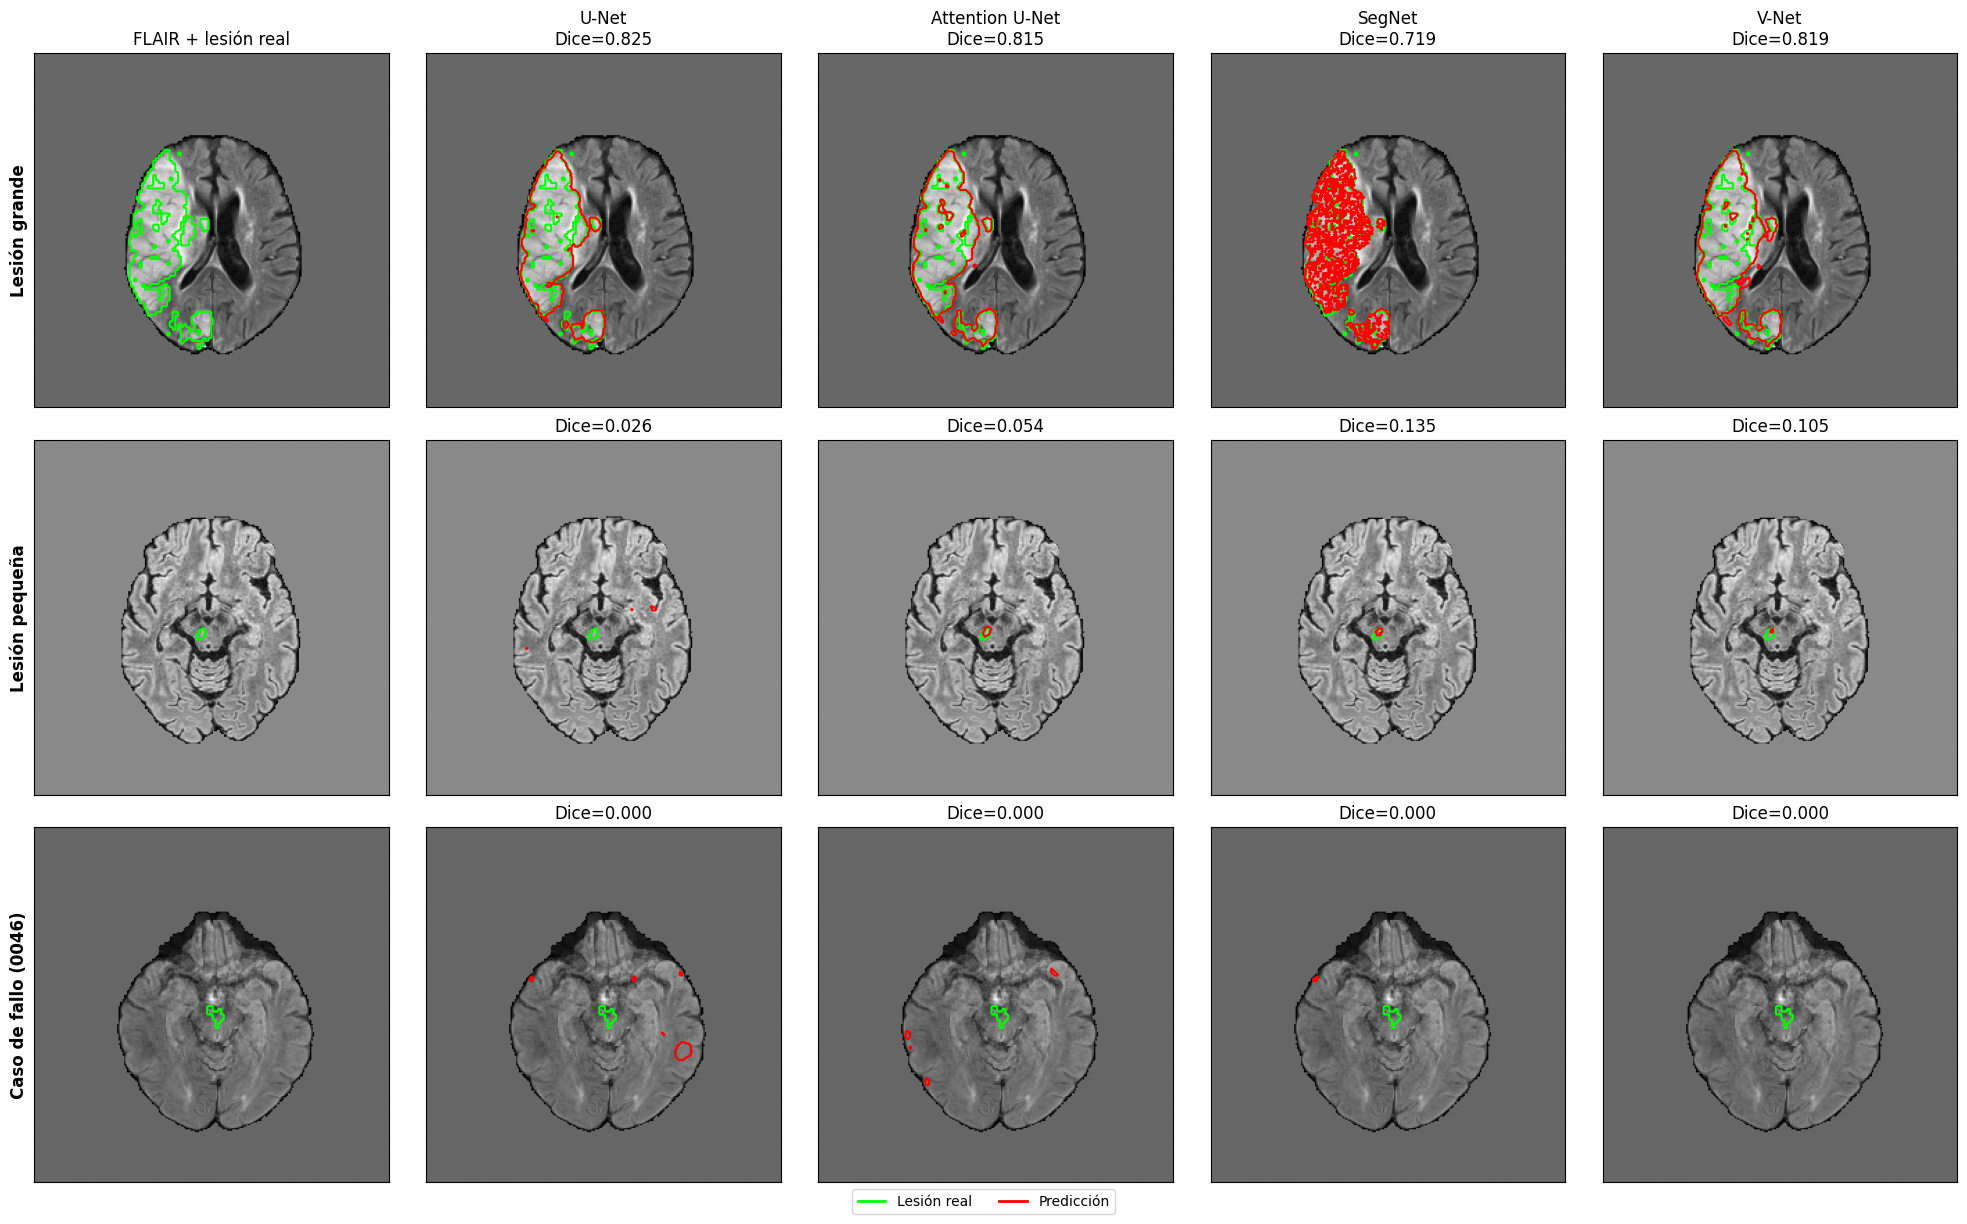

Guardada en: /content/drive/MyDrive/TFM/resultados/comparacion_3_pacientes.png


In [ ]:
# =============================================================================
# FIGURA COMPARATIVA: 3 pacientes x 4 arquitecturas
# Requiere: dir_npy (carpeta local con los *_proc.npy de test),
#           dir_resultados (carpeta con best_<modelo>.pth), device
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
import evaluacion as ev   # <-- ajusta el alias si es distinto en tu notebook

PACIENTES = [
    ("sub-strokecase0201", "Lesión grande"),
    ("sub-strokecase0115", "Lesión pequeña"),
    ("sub-strokecase0046", "Caso de fallo (0046)"),
]
MODELOS = ["UNet_2D", "AttentionUNet_2D", "SegNet_2D", "VNet_2D"]
NOMBRES_BONITOS = {"UNet_2D": "U-Net", "AttentionUNet_2D": "Attention U-Net",
                   "SegNet_2D": "SegNet", "VNet_2D": "V-Net"}

# Carga los 4 modelos una sola vez
modelos_cargados = {m: ev.cargar_modelo(m, dir_resultados='/content/drive/MyDrive/TFM/resultados', device='cuda')[0] for m in MODELOS}

fig, axes = plt.subplots(len(PACIENTES), len(MODELOS) + 1,
                         figsize=(4 * (len(MODELOS) + 1), 4 * len(PACIENTES)))

for fila, (sid, etiqueta) in enumerate(PACIENTES):
    dwi   = np.load(f"{DIR_NPY_TEST}/{sid}_dwi_proc.npy")
    adc   = np.load(f"{DIR_NPY_TEST}/{sid}_ADC_proc.npy")
    flair = np.load(f"{DIR_NPY_TEST}/{sid}_FLAIR_proc.npy")
    gt    = np.load(f"{DIR_NPY_TEST}/{sid}_msk_proc.npy") > 0

    # Corte con más lesión real (mismo criterio que diagnostico_alineacion)
    z = int(np.argmax(gt.reshape(gt.shape[0], -1).sum(axis=1)))

    # --- Columna 0: FLAIR + contorno de la lesión real ---
    ax = axes[fila, 0]
    ax.imshow(flair[z], cmap="gray")
    if gt[z].any():
        ax.contour(gt[z], colors="lime", linewidths=1.5)
    ax.set_ylabel(etiqueta, fontsize=12, fontweight="bold")
    ax.set_title("FLAIR + lesión real" if fila == 0 else "")
    ax.set_xticks([]); ax.set_yticks([])

    # --- Columnas 1-4: predicción de cada modelo ---
    for col, m in enumerate(MODELOS, start=1):
        pred = ev.predecir_volumen(modelos_cargados[m], dwi, adc, flair, device)
        dice = ev.metricas_volumen(pred, gt)["dice"]

        ax = axes[fila, col]
        ax.imshow(flair[z], cmap="gray")
        if gt[z].any():
            ax.contour(gt[z], colors="lime", linewidths=1.5)      # real = verde
        if pred[z].any():
            ax.contour(pred[z], colors="red", linewidths=1.5)     # predicción = rojo
        ax.set_title(f"{NOMBRES_BONITOS[m]}\nDice={dice:.3f}" if fila == 0
                     else f"Dice={dice:.3f}")
        ax.set_xticks([]); ax.set_yticks([])

# Leyenda común
from matplotlib.lines import Line2D
leyenda = [Line2D([0], [0], color="lime", lw=2, label="Lesión real"),
          Line2D([0], [0], color="red", lw=2, label="Predicción")]
fig.legend(handles=leyenda, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
ruta_salida = f"{dir_resultados}/comparacion_3_pacientes.png"
plt.savefig(ruta_salida, dpi=200, bbox_inches="tight")
plt.show()
print("Guardada en:", ruta_salida)

In [11]:
%pip install -q monai

from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/TFM')
import evaluacion as ev

# Copiar solo el paciente 0046 al disco local, con el mismo formato que usó la evaluación
ev.preparar_test(['sub-strokecase0046'],
                 '/content/drive/MyDrive/TFM/ISLES-2022_Preprocessed_v2',
                 '/content/npy_test')

!python /content/drive/MyDrive/TFM/caso_0046_cortes.py

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  1/1 sujetos de test | disco libre 246.3 GB
sub-strokecase0046: forma (130, 256, 256), lesión real 0.368 mL en los cortes [44, 45, 46, 47, 48, 49, 50, 51]
I0000 00:00:1793663049.275088   51808 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793663051.556659   51808 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvjpeg2k library! Please install nvJPEG2000 (see https://docs.nvidia.com/cuda/nvjpeg2000/userguide.html#installing-nvjpeg2000).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvJPEG2000 wheel: e.g. `python3 -m pip install nvidia-nvjpeg2k-cu1